In [ ]:
from google.colab import drive
import os
import shutil

# 1. Google Drive'ı Bağla
drive.mount('/content/drive')

# 2. Drive'dan yedeklenen dosyaları yerel disk alanına kopyala
print("Yedek dosyaları Google Drive'dan indiriliyor...")
shutil.copy('/content/drive/My Drive/opencv_cuda/cv2_cuda_backup.zip', '/content/')
shutil.copy('/content/drive/My Drive/opencv_cuda/opencv_libs_backup.zip', '/content/')

# 3. Python paket klasörünü oluştur ve dosyaları çıkart
print("Python cv2 paketi kuruluyor...")
os.makedirs('/usr/local/lib/python3.13/dist-packages/cv2', exist_ok=True)
!unzip -q -o /content/cv2_cuda_backup.zip -d /usr/local/lib/python3.13/dist-packages/cv2

# 4. Paylaşılan C++ kütüphanelerini çıkart
print("Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...")
!unzip -q -o /content/opencv_libs_backup.zip -d /usr/local/lib

# 5. Sistem dinamik kütüphane bağlayıcısını güncelle
print("Kütüphane yolları sistemde güncelleniyor...")
!ldconfig

# 6. Test Et
print("\n=== KURULUM TAMAMLANDI ===")
import cv2
cuda_devices = cv2.cuda.getCudaEnabledDeviceCount()
print(f"CUDA Destekli Cihaz Sayısı: {cuda_devices}")
if cuda_devices > 0:
    print("Tebrikler! OpenCV CUDA desteğiyle başarıyla geri yüklendi.")
    cv2.cuda.printCudaDeviceInfo(0)
else:
    print("Uyarı: Kurulum tamamlandı ancak GPU etkinleştirilmemiş olabilir. Runtime ayarlarından GPU seçtiğinize emin olun.")

Mounted at /content/drive
Yedek dosyaları Google Drive'dan indiriliyor...
Python cv2 paketi kuruluyor...
Sistem paylaşımlı kütüphaneleri (.so) geri yükleniyor...
Kütüphane yolları sistemde güncelleniyor...
/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_level_zero_v2.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_opencl.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libjulia.so.1.12 is not a sym

Resim başarıyla yüklendi!
Resim boyutu: (64, 64)

2 Boyutlu DFT işlemi tamamlandı!
Harmonik vektörünün boyutu: (4096,)

İlk 10 harmonik değeri:
[479248.            +0.j          31314.35034547+22329.3197686j
  -5231.00545453+35297.47720499j -13910.11003549  -814.34989364j
   -507.74841126+13738.82638677j -12058.87432547 +7211.48943309j
   2682.21689832-25077.91813797j  17803.2880969  +5736.54788737j
  -8327.64501988+14951.09046538j -10859.64705107  +391.85387296j]


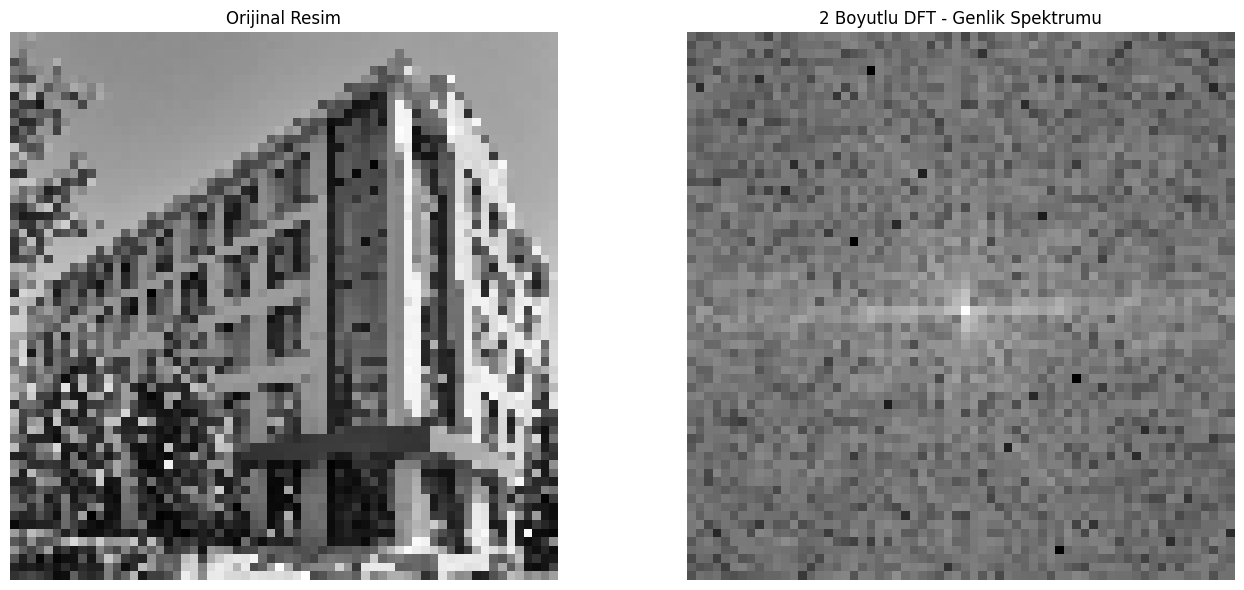


Harmonik vektörü başarıyla kaydedildi!
Dosya: /content/harmonik_vektoru.npy

İŞLEM TAMAMLANDI!


In [11]:

import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

# ==========================================
# 1. RESMİ OKU
# ==========================================

resim_yolu = "/content/resim7.jpg"

resim = np.array(
    Image.open(resim_yolu).convert("L")
)

print("Resim başarıyla yüklendi!")

# Resmi 64x64 boyutuna küçült
resim = cv2.resize(resim, (64, 64))

print("Resim boyutu:", resim.shape)


# ==========================================
# 2. 2 BOYUTLU DFT FONKSİYONU
# ==========================================

def iki_boyutlu_dft(resim):

    M, N = resim.shape

    resim = np.asarray(resim, dtype=np.float64)

    # Satırlar için DFT matrisi
    Wm = np.exp(
        -2j * np.pi *
        np.outer(np.arange(M), np.arange(M)) / M
    )

    # Sütunlar için DFT matrisi
    Wn = np.exp(
        -2j * np.pi *
        np.outer(np.arange(N), np.arange(N)) / N
    )

    # İki boyutlu DFT hesaplama
    F = Wm @ resim @ Wn.T

    # Harmonik vektörünü oluştur
    harmonik_vektoru = F.flatten()

    return harmonik_vektoru


# ==========================================
# 3. DFT FONKSİYONUNU ÇALIŞTIR
# ==========================================

harmonik_vektoru = iki_boyutlu_dft(resim)

print("\n2 Boyutlu DFT işlemi tamamlandı!")

print("Harmonik vektörünün boyutu:",
      harmonik_vektoru.shape)

print("\nİlk 10 harmonik değeri:")
print(harmonik_vektoru[:10])


# ==========================================
# 4. HARMONİK VEKTÖRÜNÜ 2 BOYUTLU YAP
# ==========================================

F = harmonik_vektoru.reshape(64, 64)

# Düşük frekansları merkeze taşı
F_shifted = np.fft.fftshift(F)

# Genlik spektrumunu hesapla
genlik_spektrumu = np.log1p(
    np.abs(F_shifted)
)


# ==========================================
# 5. SONUÇLARI GÖRSELLEŞTİR
# ==========================================

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(resim, cmap="gray")
plt.title("Orijinal Resim")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(genlik_spektrumu, cmap="gray")
plt.title("2 Boyutlu DFT - Genlik Spektrumu")
plt.axis("off")

plt.tight_layout()
plt.show()


# ==========================================
# 6. HARMONİK VEKTÖRÜNÜ KAYDET
# ==========================================

np.save(
    "/content/harmonik_vektoru.npy",
    harmonik_vektoru
)

print("\nHarmonik vektörü başarıyla kaydedildi!")
print("Dosya: /content/harmonik_vektoru.npy")

print("\nİŞLEM TAMAMLANDI!")

